## REFERENCES
* https://chatgpt.com

# Goal
The objective of this study is to perform customer segmentation using unsupervised learning techniques in order to identify distinct behavioral groups within the customer base.
The goal is to:

* Understand purchasing behavior patterns
* Identify high-value and low-value customers
* Support targeted marketing strategies
* Improve retention and revenue optimization

In [66]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans, DBSCAN
from sklearn.manifold import TSNE

In [67]:
df = pd.read_excel("Online Retail.xlsx")

# Exploratory data analysis

In [68]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [69]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [70]:
print("Number of CustomerID : ", df['CustomerID'].unique().shape[0])
print("Number of Country : ", df['Country'].unique().shape[0])

Number of CustomerID :  4373
Number of Country :  38


In [71]:
print('Columns type :')
df.dtypes

Columns type :


InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [72]:
print("Columns with NULL values :")
print(df.isnull().sum())
print("\nCounts :")
print(df.count())

Columns with NULL values :
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Counts :
InvoiceNo      541909
StockCode      541909
Description    540455
Quantity       541909
InvoiceDate    541909
UnitPrice      541909
CustomerID     406829
Country        541909
dtype: int64


> ## Data cleaning

In [73]:
df = df[df['Quantity'] > 0]
df = df.dropna(subset=['CustomerID'])

In [74]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,397924.000000,397924,397924.000000,397924.000000
mean,13.021823,2011-07-10 23:43:36.912475648,3.116174,15294.315171
min,1.000000,2010-12-01 08:26:00,0.000000,12346.000000
25%,2.000000,2011-04-07 11:12:00,1.250000,13969.000000
50%,6.000000,2011-07-31 14:39:00,1.950000,15159.000000
75%,12.000000,2011-10-20 14:33:00,3.750000,16795.000000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000
std,180.420210,NaN,22.096788,1713.169877


In [75]:
print("Columns with NULL values :")
print(df.isnull().sum())
print("\nCounts :")
print(df.count())

Columns with NULL values :
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Counts :
InvoiceNo      397924
StockCode      397924
Description    397924
Quantity       397924
InvoiceDate    397924
UnitPrice      397924
CustomerID     397924
Country        397924
dtype: int64


Invoice per country :
 Country
United Kingdom          16649
Germany                   457
France                    389
EIRE                      260
Belgium                    98
Netherlands                95
Spain                      90
Portugal                   57
Australia                  57
Switzerland                51
Finland                    41
Italy                      38
Sweden                     36
Norway                     36
Channel Islands            26
Japan                      19
Poland                     19
Denmark                    18
Austria                    17
Cyprus                     16
Unspecified                 8
Iceland                     7
Singapore                   7
Canada                      6
Greece                      5
Malta                       5
Israel                      5
USA                         5
Lithuania                   4
European Community          4
United Arab Emirates        3
Czech Republic              2
Bahrain  

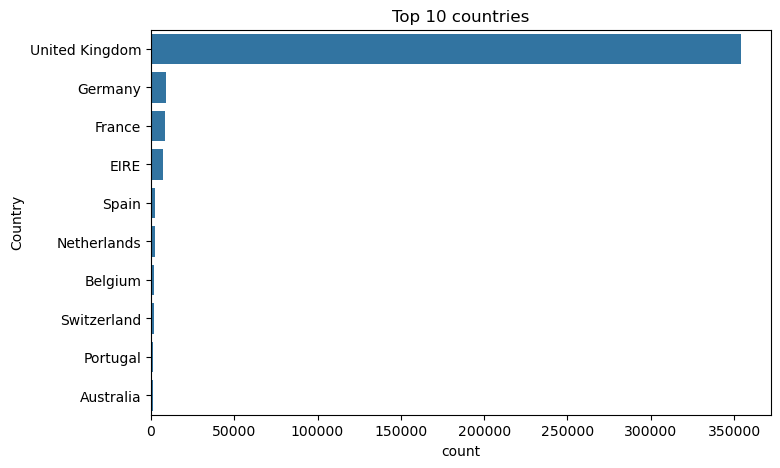

In [76]:
print("Invoice per country :\n", df.groupby('Country')['InvoiceNo'].nunique().sort_values(ascending=False))
plt.figure(figsize=(8,5))
sns.countplot(y="Country", data=df, order=df["Country"].value_counts().index[:10])
plt.title("Top 10 countries")
plt.show()

In [77]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
client_df = df.groupby('CustomerID').agg({
    'InvoiceNo': 'nunique',          # Frequency
    'TotalPrice': 'sum',             # Monetary
    'Quantity': 'sum',               # Volume d'achat
    'InvoiceDate': lambda x: (df['InvoiceDate'].max() - x.max()).days  # Recency
})

client_df.rename(columns={
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'Monetary',
    'Quantity': 'TotalQuantity',
    'InvoiceDate': 'Recency'
}, inplace=True)

In [78]:
client_df.describe()

,Frequency,Monetary,TotalQuantity,Recency
count,4339.000000,4339.000000,4339.000000,4339.000000
mean,4.271952,2053.793018,1194.214335,91.518322
std,7.705493,8988.248381,5055.603049,100.009747
min,1.000000,0.000000,1.000000,0.000000
25%,1.000000,307.245000,160.000000,17.000000
50%,2.000000,674.450000,379.000000,50.000000
75%,5.000000,1661.640000,993.000000,141.000000
max,210.000000,280206.020000,197491.000000,373.000000


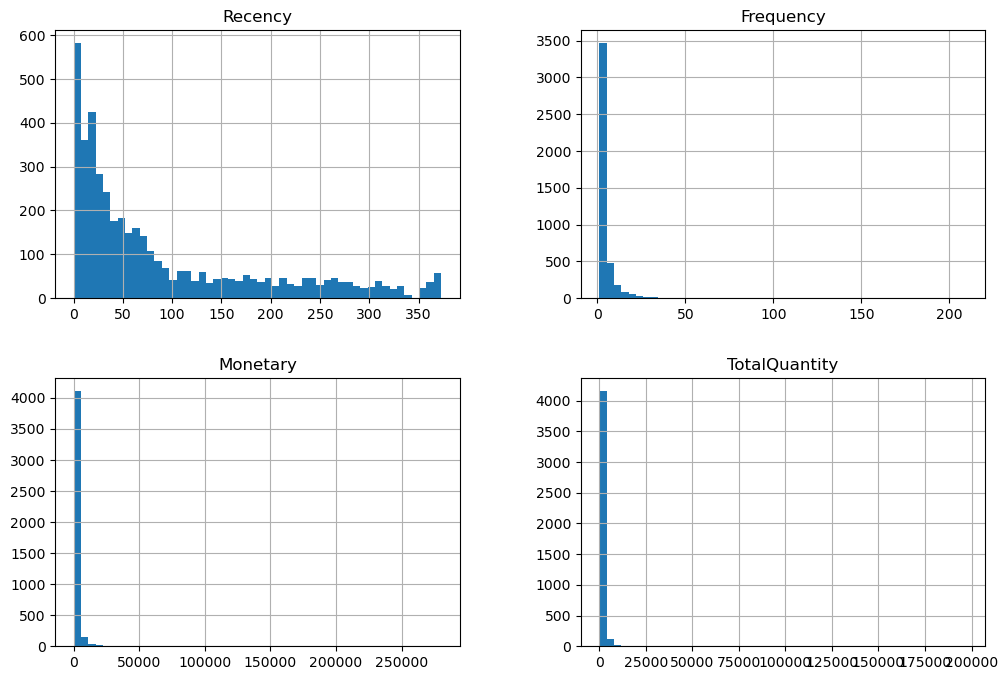

In [79]:
client_df[['Recency','Frequency','Monetary','TotalQuantity']].hist(bins=50, figsize=(12,8))
plt.show()

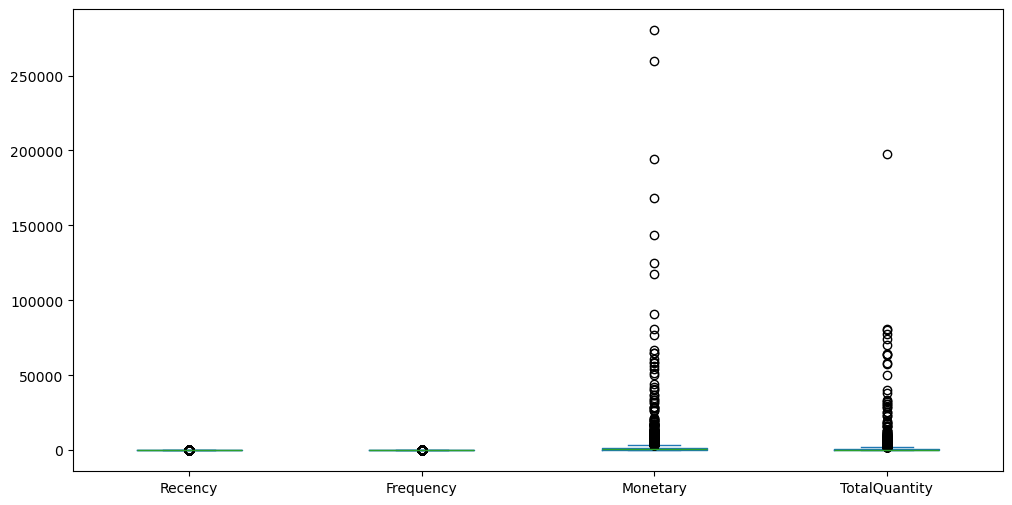

In [80]:
client_df[['Recency','Frequency','Monetary','TotalQuantity']].plot(kind='box', figsize=(12,6))
plt.show()

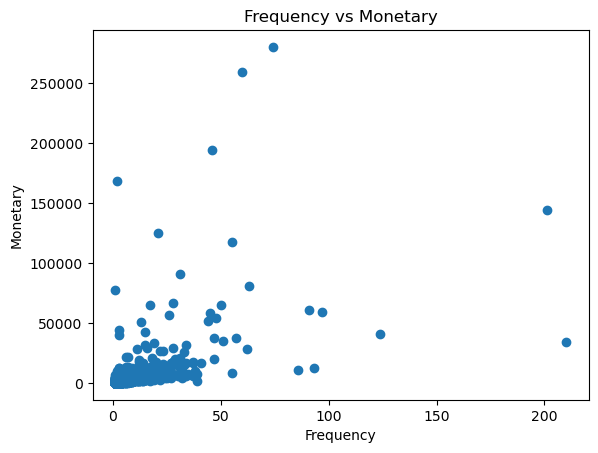

In [81]:
plt.scatter(client_df['Frequency'], client_df['Monetary'])
plt.xlabel('Frequency')
plt.ylabel('Monetary')
plt.title('Frequency vs Monetary')
plt.show()

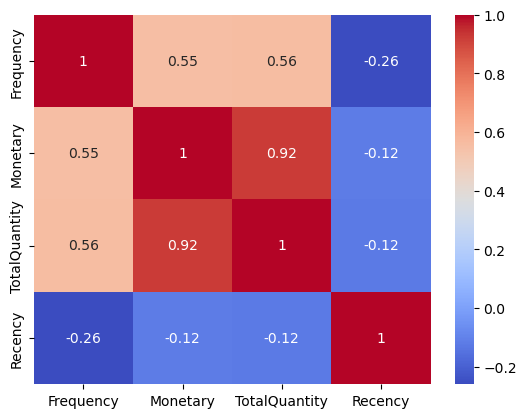

In [82]:
sns.heatmap(client_df.corr(), annot=True, cmap='coolwarm')
plt.show()

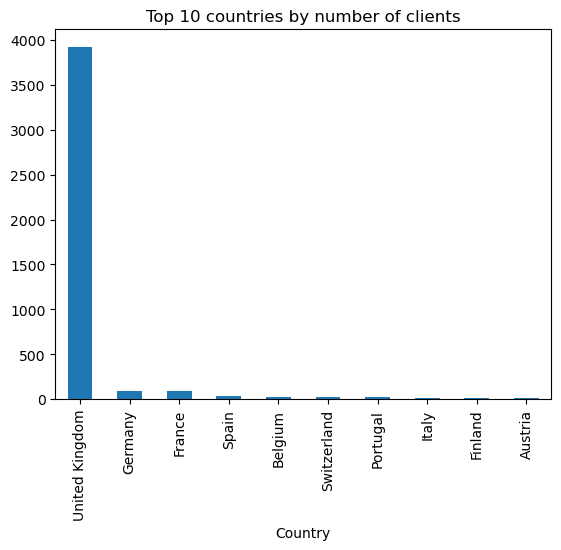

In [83]:
clients_country = df.groupby('Country')['CustomerID'].nunique().sort_values(ascending=False)
clients_country.head(10).plot(kind='bar')
plt.title('Top 10 countries by number of clients')
plt.show()

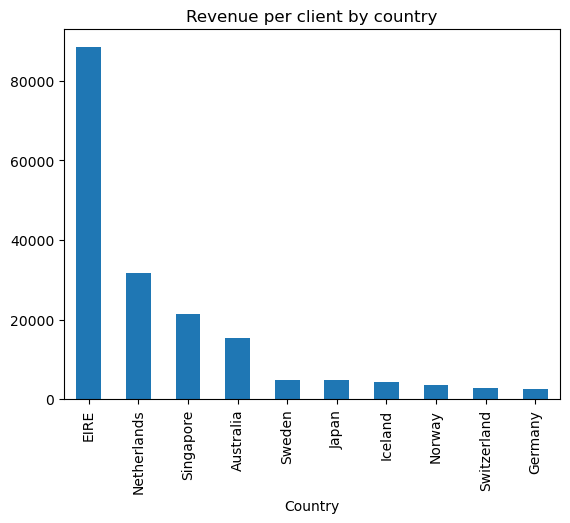

In [84]:
revenue_country = df.groupby('Country')['TotalPrice'].sum() / df.groupby('Country')['CustomerID'].nunique()
revenue_country.sort_values(ascending=False).head(10).plot(kind='bar')
plt.title('Revenue per client by country')
plt.show()

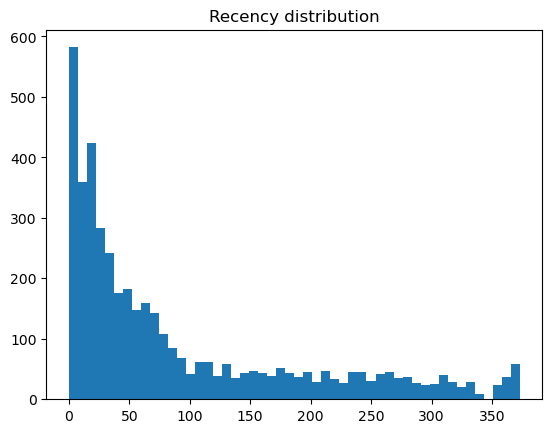

In [85]:
plt.hist(client_df['Recency'], bins=50)
plt.title('Recency distribution')
plt.show()

In [86]:
# Montant moyen par commande
client_df['AvgBasket'] = client_df['Monetary'] / client_df['Frequency']

# Quantité moyenne par commande
client_df['AvgQuantity'] = client_df['TotalQuantity'] / client_df['Frequency']

# Atténuer l’effet des valeurs extrêmes sur Recency
client_df['RecencyScore'] = np.log1p(client_df['Recency'])  # log(Recency + 1)

In [87]:
client_df[['Monetary','Frequency','TotalQuantity','Recency','AvgBasket','AvgQuantity','RecencyScore']].head()

,Monetary,Frequency,TotalQuantity,Recency,AvgBasket,AvgQuantity,RecencyScore
CustomerID,,,,,,,
12346.0,77183.60,1,74215,325,77183.600000,74215.000000,5.786897
12347.0,4310.00,7,2458,1,615.714286,351.142857,0.693147
12348.0,1797.24,4,2341,74,449.310000,585.250000,4.317488
12349.0,1757.55,1,631,18,1757.550000,631.000000,2.944439
12350.0,334.40,1,197,309,334.400000,197.000000,5.736572


> ## Standardization

In [88]:
features = ['RecencyScore', 'Frequency', 'Monetary', 'AvgBasket', 'AvgQuantity']
rfm = client_df[features]
rfm_log = np.log1p(rfm)
scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)

# Clustering

> ## Modeling

## KMEANS

k=2, silhouette=0.319
k=3, silhouette=0.280
k=4, silhouette=0.255
k=5, silhouette=0.249
k=6, silhouette=0.257
k=7, silhouette=0.233
k=8, silhouette=0.242
k=9, silhouette=0.231


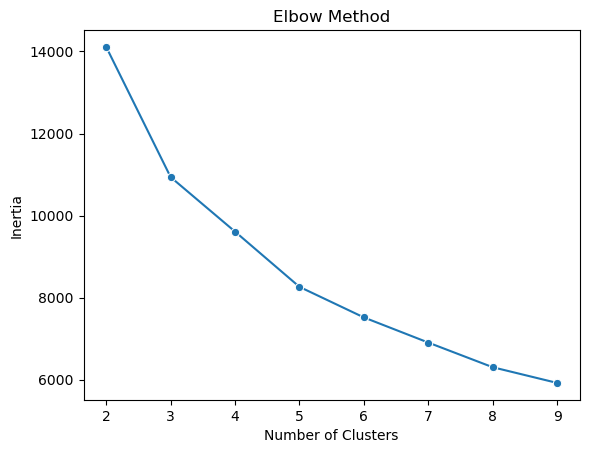

In [89]:
k_values = range(2, 10)
inertia = []
for k in k_values:
    cls = KMeans(n_clusters=k, random_state=42)
    kmeans = cls.fit(X)
    score = silhouette_score(X, kmeans.labels_)
    inertia.append(kmeans.inertia_)
    print(f"k={k}, silhouette={score:.3f}")

sns.lineplot(x=range(2,10), y=inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

In [90]:
cls = KMeans(n_clusters=4, random_state=42)
labels = cls.fit_predict(X)

In [91]:
client_df['Cluster'] = labels

In [92]:
silhouette_score(X, labels)

0.2549665787114713

> ## Interpretation

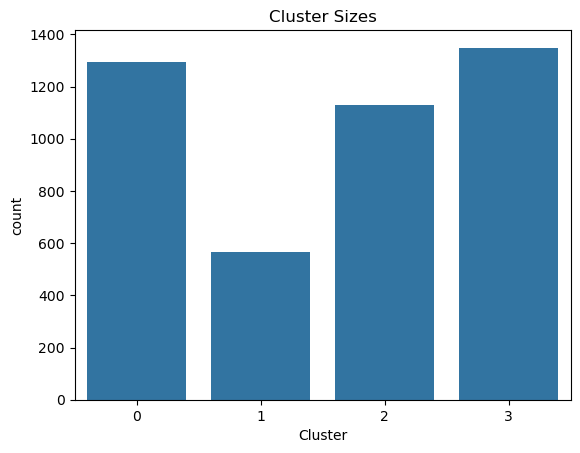

In [93]:
sns.countplot(x="Cluster", data=client_df)
plt.title("Cluster Sizes")
plt.show()

In [94]:
cluster_summary = client_df.groupby('Cluster').mean()
print(cluster_summary)

         Frequency     Monetary  TotalQuantity     Recency   AvgBasket  \
Cluster                                                                  
0         1.598918   235.186840     131.285162  146.613601  157.598431   
1        14.617958  9642.980563    5498.010563    9.690141  740.136059   
2         5.085106  1368.568290     776.848404   37.473404  274.932278   
3         1.799852  1175.773271     750.673091  118.314307  655.148047   

         AvgQuantity  RecencyScore  
Cluster                             
0          91.553047      4.545088  
1         418.646619      1.740313  
2         157.332693      3.137762  
3         428.772294      4.401010  


**Cluster 0** : Occasional and low-spending customers, somewhat inactive.

**Cluster 1** : VIP clients or rare high-value buyers with infrequent but massive purchases.

**Cluster 2** : Active and frequent buyers with moderate spending.

**Cluster 3** : Super active VIP clients, high-frequency and high-spending.


# Dimensionality reduction

## PCA

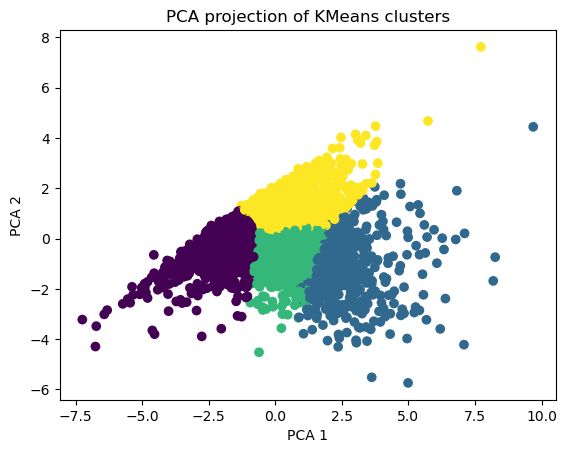

In [95]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# plt.figure(figsize=(8,6))
plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=client_df['Cluster'])
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("PCA projection of KMeans clusters")
plt.show()

## TSNE

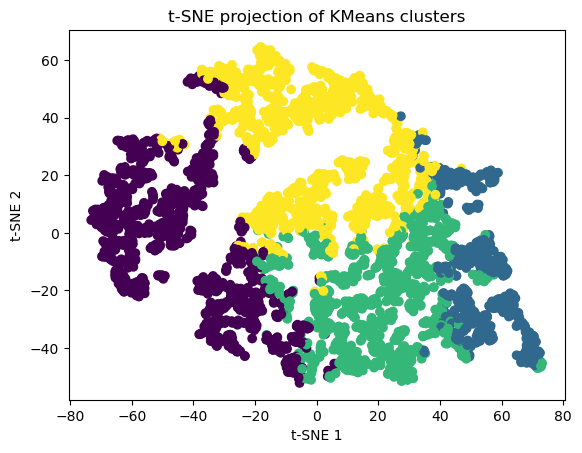

In [96]:
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

plt.figure()
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=client_df['Cluster'])
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE projection of KMeans clusters")
plt.show()

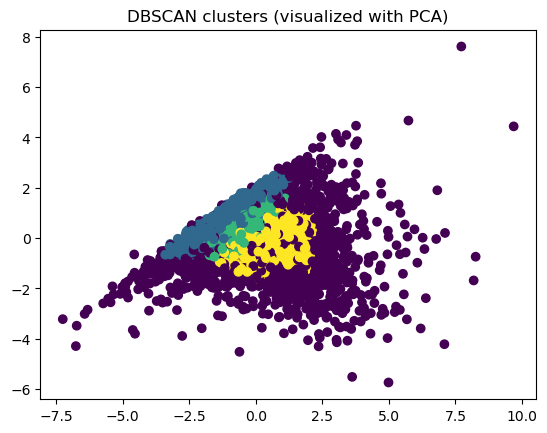

In [97]:
db = DBSCAN(eps=0.5, min_samples=30)
labels_db = db.fit_predict(X)

plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_db)
plt.title("DBSCAN clusters (visualized with PCA)")
plt.show()

In [98]:
client_df["Cluster-DBSCAN"] = labels_db
cluster_summary = client_df.groupby('Cluster-DBSCAN').mean()
print(cluster_summary)

                Frequency     Monetary  TotalQuantity     Recency   AvgBasket  \
Cluster-DBSCAN                                                                  
-1               7.585250  4425.814798    2563.520974   52.574425  622.712875   
 0               1.000000   309.827912     180.974089  164.744939  309.827912   
 1               2.000000   587.912348     348.269565  102.911304  293.956174   
 2               4.700285  1569.330696     922.030447   54.004757  329.415867   

                AvgQuantity  RecencyScore   Cluster  
Cluster-DBSCAN                                       
-1               396.332284      2.822640  1.369418  
 0               180.974089      4.777806  1.413765  
 1               174.134783      4.248482  1.782609  
 2               192.898581      3.644976  1.975262  
